# Multi-Layer Perceptrons (MLPs): Bending Space & Solving XOR

In the previous chapter (**The Perceptron**), we saw that **one artificial neuron = one straight line**. That solved `AND`, `OR`, `NOT`, `NAND`, and `NOR` — but hit a brick wall on **`XOR`** (`50%` guessing!).

### The Big Idea: Wire Neurons Into Layers!
What happens if we feed the outputs of two perceptrons into a **third** perceptron?
Look at `XOR` ("one or the other, **but not both**") in plain English:
- **Hidden Neuron 1 (`OR`):** *"Is at least one input `1`?"*
- **Hidden Neuron 2 (`NAND`):** *"Are they NOT both `1`?"*
- **Output Neuron (`AND`):** *"Are BOTH of those answers true?"*

That 2-layer team of 3 tiny perceptrons **IS a Multi-Layer Perceptron (MLP)**! Let's run it right now.


In [1]:
import sys
from pathlib import Path

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import math, random
import vknumpy as vnp
from PIL import Image, ImageDraw
from IPython.display import display

def perceptron(x1, x2, w1, w2, b):
    return 1 if (w1 * x1 + w2 * x2 + b) >= 0 else 0

def xor_mlp(x1, x2):
    # Hidden Layer: two neurons running in parallel
    h1 = perceptron(x1, x2, w1= 1.0, w2= 1.0, b=-0.5)   # OR   neuron
    h2 = perceptron(x1, x2, w1=-1.0, w2=-1.0, b= 1.5)   # NAND neuron
    # Output Layer: combines the hidden layer's votes
    out = perceptron(h1, h2, w1=1.0, w2=1.0, b=-1.5)    # AND  neuron
    return h1, h2, out

print("=== 2-Layer MLP Solving XOR by Hand (OR + NAND -> AND) ===")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    h1, h2, out = xor_mlp(x1, x2)
    print(f"  x=({x1}, {x2})  ->  hidden=[OR:{h1}, NAND:{h2}]  ->  XOR = {out}")


=== 2-Layer MLP Solving XOR by Hand (OR + NAND -> AND) ===
  x=(0, 0)  ->  hidden=[OR:0, NAND:1]  ->  XOR = 0
  x=(0, 1)  ->  hidden=[OR:1, NAND:1]  ->  XOR = 1
  x=(1, 0)  ->  hidden=[OR:1, NAND:1]  ->  XOR = 1
  x=(1, 1)  ->  hidden=[OR:1, NAND:0]  ->  XOR = 0


---
## Step 1: Why Activation Functions (`GELU` / `ReLU`) Are Mandatory!

When we train an MLP on a GPU with `vktorch`, we don't hand-pick `OR` and `NAND` weights — we let backpropagation **learn** the hidden layer automatically!

**One crucial catch:** If you stack `nn.Linear` layers *without* a non-linear **activation function** (`GELU`, `ReLU`, `SiLU`) between them, the math collapses:
> *A straight line of a straight line is still just **one straight line**!*

Watch what happens on `XOR` when we train a 2-layer network **without** an activation vs. **with** our fused SPIR-V `nn.GELU()`!


In [2]:
import vklearn as vkl
import vktorch as vt
from vktorch import nn, optim

X_xor = vt.tensor([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = vt.tensor([[0], [1], [1], [0]])
loss_fn = nn.BCEWithLogitsLoss()

def train_xor(model, steps=250, lr=0.15):
    opt = optim.AdamW(model.parameters(), lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        loss = loss_fn(model(X_xor), y_xor)
        loss.backward()
        opt.step()
    with vt.no_grad():
        probs = model(X_xor).sigmoid().data.reshape(-1)
    preds = (probs >= 0.5).astype(int)
    acc = float(vkl.accuracy_score(y_xor.data.reshape(-1), preds))
    return probs, acc

# 1. Stacked Linear layers with NO activation -> collapses to 1 straight line!
linear_only = nn.Sequential(nn.Linear(2, 8, seed=1), nn.Linear(8, 1, seed=2))
p_lin, acc_lin = train_xor(linear_only)

# 2. Same exact layers + ONE nn.GELU() activation -> bends space and solves XOR!
mlp_gelu = nn.Sequential(nn.Linear(2, 8, seed=1), nn.GELU(), nn.Linear(8, 1, seed=2))
p_mlp, acc_mlp = train_xor(mlp_gelu)

print(f"Linear-only (no activation) -> probs={[round(float(v), 2) for v in p_lin]} | Accuracy = {acc_lin:.0%}")
print(f"2-Layer MLP (with GELU)     -> probs={[round(float(v), 2) for v in p_mlp]} | Accuracy = {acc_mlp:.0%}")


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Linear-only (no activation) -> probs=[0.5, 0.5, 0.5, 0.5] | Accuracy = 50%
2-Layer MLP (with GELU)     -> probs=[0.0, 1.0, 1.0, 0.0] | Accuracy = 100%


---
## Step 2: Expanding on MLPs — Width, Depth & Bending Curved Boundaries!

`XOR` only has 4 points. What about a real curved dataset where one class is trapped **inside a ring** surrounded by the other class (**Concentric Circles**)?

No single straight line can separate a circle from the ring around it — a single perceptron gets stuck near `50%`!
Let's compare **3 models** on our Vulkan GPU so you can literally *see* what **hidden-layer width** and **depth** do:
1. **Single Neuron (`vklearn.LogisticRegression`):** 1 straight line → fails (~50%).
2. **Tiny MLP (`2 → 4 → 1`):** 1 hidden layer of just **4 neurons** → combines 4 bent lines into a rough polygon around the inner circle!
3. **Deep MLP (`2 → 32 → 32 → 1` with `GELU`):** 2 hidden layers of **32 neurons** → sculpts a smooth circular boundary (**~100% accuracy**)!


1. Single Neuron (LogisticReg)   -> Accuracy =  55.3%
2. Tiny MLP (2 -> 4 -> 1)        -> Accuracy = 100.0%  (17 params)
3. Deep MLP (2 -> 32 -> 32 -> 1) -> Accuracy = 100.0%  (1185 params)


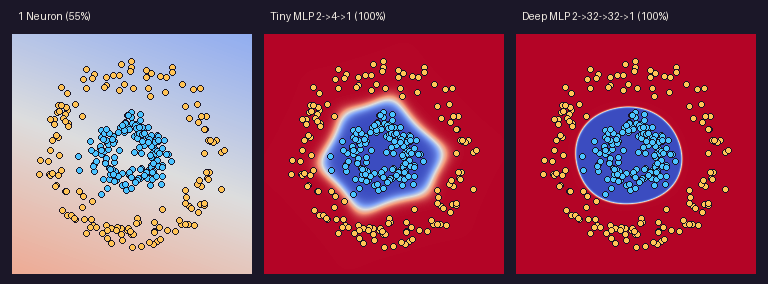

In [3]:
import vklearn as vkl
import vkcolorcet as vkc

# Create 300 concentric-circle points (Blue = inner circle 0, Orange = outer ring 1)
rng = random.Random(42)
n_half = 150
pts0 = [[r * math.cos(t), r * math.sin(t)]
        for t, r in ((rng.uniform(0, 2 * math.pi), rng.gauss(0.55, 0.14)) for _ in range(n_half))]
pts1 = [[r * math.cos(t), r * math.sin(t)]
        for t, r in ((rng.uniform(0, 2 * math.pi), rng.gauss(1.55, 0.16)) for _ in range(n_half))]
pts_ring = pts0 + pts1
lbl_ring = [0] * n_half + [1] * n_half
X_ring = vnp.array(pts_ring)
y_ring = vnp.array(lbl_ring)

# =====================================================================
# PART A: Train 3 models (1 Neuron vs Tiny MLP vs Deep MLP) on GPU
# =====================================================================
solo_clf = vkl.LogisticRegression().fit(X_ring, y_ring)

def train_ring_mlp(model, steps=180, lr=0.05):
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
    Xt, yt = vt.tensor(X_ring), vt.tensor(y_ring.reshape(-1, 1))
    for _ in range(steps):
        opt.zero_grad()
        loss_fn(model(Xt), yt).backward()
        opt.step()
    with vt.no_grad():
        acc = vkl.accuracy_score(y_ring, (model(Xt).data.reshape(-1) >= 0))
    return model, acc

tiny_mlp, acc_tiny = train_ring_mlp(nn.Sequential(
    nn.Linear(2, 4, seed=3), nn.GELU(), nn.Linear(4, 1, seed=4)
))
deep_mlp, acc_deep = train_ring_mlp(nn.Sequential(
    nn.Linear(2, 32, seed=5), nn.GELU(),
    nn.Linear(32, 32, seed=6), nn.GELU(),
    nn.Linear(32, 1, seed=7),
))

print(f"1. Single Neuron (LogisticReg)   -> Accuracy = {solo_clf.score(X_ring, y_ring):6.1%}")
print(f"2. Tiny MLP (2 -> 4 -> 1)        -> Accuracy = {acc_tiny:6.1%}  ({tiny_mlp.num_parameters()} params)")
print(f"3. Deep MLP (2 -> 32 -> 32 -> 1) -> Accuracy = {acc_deep:6.1%}  ({deep_mlp.num_parameters()} params)")

# =====================================================================
# PART B: Visualize the 3 decision boundaries using vkcolorcet
# =====================================================================
pw, ph = 240, 240
xs_g = [-2.3 + 4.6 * i / (pw - 1) for i in range(pw)]
ys_g = [ 2.3 - 4.6 * j / (ph - 1) for j in range(ph)]
grid = vnp.array([[x, y] for y in ys_g for x in xs_g])
lut = vkc.get_rgb_lut("coolwarm")

def render_panel(title, probs_2d):
    rgb = lut[vnp.clip((probs_2d * 255.0), 0, 255).to_numpy().astype(int)].copy()
    im = Image.fromarray(rgb, mode="RGB")
    dr = ImageDraw.Draw(im)
    for xi, yi in zip(pts_ring, lbl_ring):
        px = int((xi[0] + 2.3) / 4.6 * (pw - 1))
        py = int((2.3 - xi[1]) / 4.6 * (ph - 1))
        col = (255, 195, 85) if yi == 1 else (75, 195, 255)
        dr.ellipse((px - 3, py - 3, px + 3, py + 3), fill=col, outline=(24, 20, 36))
    return im, title

p_solo = solo_clf.predict_proba(grid)[:, 1].reshape(ph, pw)
with vt.no_grad():
    p_tiny = tiny_mlp(vt.tensor(grid)).sigmoid().data.reshape(ph, pw)
    p_deep = deep_mlp(vt.tensor(grid)).sigmoid().data.reshape(ph, pw)

cards = [
    render_panel(f"1 Neuron ({solo_clf.score(X_ring, y_ring):.0%})", p_solo),
    render_panel(f"Tiny MLP 2->4->1 ({acc_tiny:.0%})", p_tiny),
    render_panel(f"Deep MLP 2->32->32->1 ({acc_deep:.0%})", p_deep),
]
strip = Image.new("RGB", (3 * pw + 48, ph + 44), (27, 23, 40))
dr_s = ImageDraw.Draw(strip)
for i, (im, ttl) in enumerate(cards):
    x0 = 12 + i * (pw + 12)
    strip.paste(im, (x0, 34))
    dr_s.text((x0 + 6, 10), ttl, fill=(244, 238, 228))
display(strip)


### Anatomy of an MLP (Your Cheat Sheet for the Rest of the Book)

Every Multi-Layer Perceptron — from the 17-parameter `Tiny MLP` above to the giant Feed-Forward blocks inside modern LLMs — has the exact same 4 parts:

| Part | Plain-English Role | In `vktorch` |
|---|---|---|
| **Input Layer** | The raw clues (numbers, features, or pixels) | `vt.tensor(X)` |
| **Hidden Layers (Width & Depth)** | **Width** (e.g., `4` vs `32` neurons) controls how many bends/corners each layer can draw; **Depth** (1 vs 2+ layers) lets layers combine simple shapes into complex patterns | `nn.Linear(in, hidden)` |
| **Activation Function** | Adds the essential non-linear *bend* so stacked layers don't collapse back into 1 straight line | `nn.GELU()`, `nn.ReLU()`, `nn.SiLU()` |
| **Output Layer** | Turns the hidden features into the final prediction (a house price, a probability, or 10 clothing logits) | `nn.Linear(hidden, out)` |

### Where You'll See MLPs Next in This Book
- **Chapter 2 (`HousingResNet`):** A deeper Residual MLP with `LayerNorm` + skip connections that beat Classical ML on California Housing (`$48.2k` RMSE).
- **Chapter 4 (`FashionCNN`):** Uses an MLP classifier head on top of 2D convolutional filters (`87.85%` on Fashion-MNIST).
- **Chapter 20 (`Mini-Llama`):** Every Transformer block contains a gated MLP (`SwiGLU`) that stores most of an LLM's factual knowledge!


---
### From 3 Parameters to 8 Billion: How This Connects to Large Language Models (LLMs)

Every single **weight (`w`)** and **bias (`b`)** knob a neural network tunes during training is **1 parameter** — and modern LLMs are built out of the *exact same* knobs, just scaled way up!

| Model | Architecture | Parameters (Knobs) | What It Can Sculpt |
|---|---|---:|---|
| **1 Perceptron** | `2 → 1` (`w1, w2, b`) | **3** | One straight line |
| **Tiny MLP** | `2 → 4 → 1` | **17** | A rough 4-sided diamond |
| **Deep MLP** | `2 → 32 → 32 → 1` | **1,185** | A silky-smooth circle |
| **Llama 3 8B** | `4,096`-wide × `32` blocks | **8,000,000,000** | Grammar, facts, code & reasoning |

- Instead of 2 inputs (`x1, x2`), an LLM represents each word/token as a list of **4,096 numbers** and passes it through **32 stacked Transformer blocks**.
- **Roughly two-thirds of all parameters in an LLM live inside its MLP layers** (`SwiGLU` feed-forward blocks — each expanding `4,096 → 14,336 → 4,096`, holding ~176 million weights per block!).
- Just like jumping from **17 parameters** (a boxy diamond) to **1,185 parameters** (a smooth circle) let our MLP sculpt finer shapes, scaling to **billions of parameters** gives an LLM enough `w · x + b` knobs to store language, facts, and reasoning!
